Each brain snapshot covers 1.49 secondds of video

In [1]:
import cv2, h5py, numpy as np, matplotlib.pyplot as plt

TR = 1.49
video_path = '/home/erikm/algonauts_2025.competitors/stimuli/movies/friends/s1/friends_s01e02a.mkv'

cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)
frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)
duration = frames / fps

print('FPS:', round(fps, 2))
print('Video length (s):', round(duration, 1))
print('Snapshots that fit:', round(duration / TR))

FPS: 29.97
Video length (s): 718.8
Snapshots that fit: 482


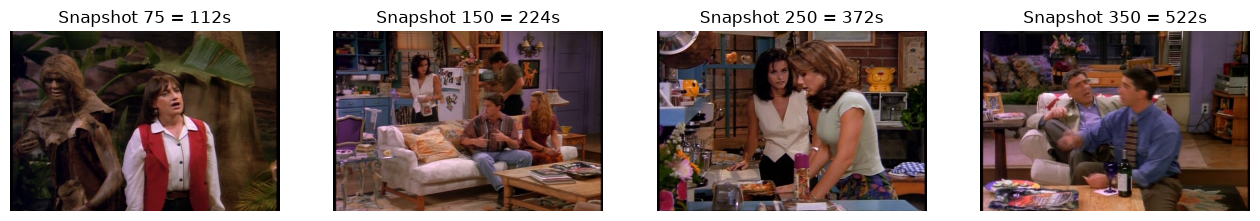

In [2]:
def frame_at(seconds):
    cap.set(cv2.CAP_PROP_POS_MSEC, seconds * 1000)
    ok, img = cap.read()
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

snapshots = [75, 150, 250, 350]
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, i in zip(axes, snapshots):
    ax.imshow(frame_at(i * TR))
    ax.set_title(f'Snapshot {i} = {i*TR:.0f}s')
    ax.axis('off')
plt.show()

Since fMRI measures blood flow, not neurons, there is a delay of around 5 seconds

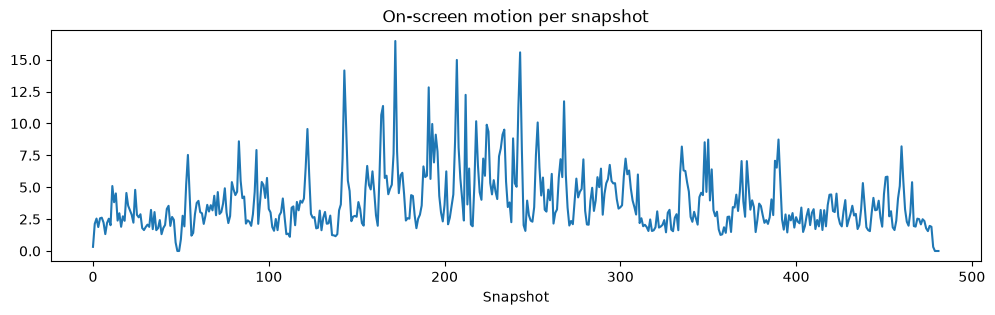

In [3]:
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
n_snap = 482
motion = np.zeros(n_snap)
counts = np.zeros(n_snap)
prev = None
f = 0
while True:
    ok, img = cap.read()
    if not ok:
        break
    small = cv2.cvtColor(cv2.resize(img, (64, 36)), cv2.COLOR_BGR2GRAY).astype(float)
    if prev is not None:
        i = min(int((f / fps) / TR), n_snap - 1)
        motion[i] += np.abs(small - prev).mean()
        counts[i] += 1
    prev = small
    f += 1
motion /= np.maximum(counts, 1)

plt.figure(figsize=(12, 3))
plt.plot(motion)
plt.title('On-screen motion per snapshot')
plt.xlabel('Snapshot')
plt.show()

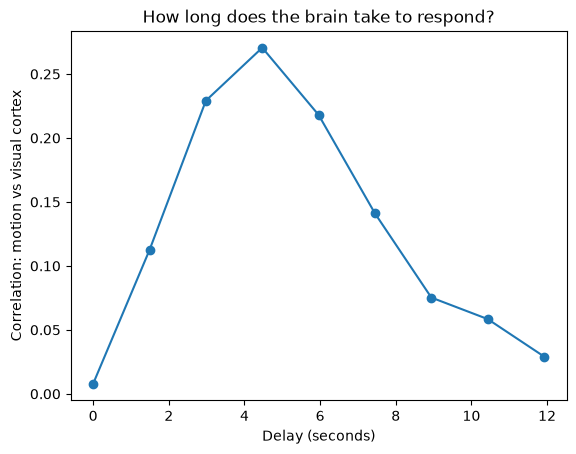

In [4]:
path = '/home/erikm/algonauts_2025.competitors/fmri/sub-01/func/sub-01_task-friends_space-MNI152NLin2009cAsym_atlas-Schaefer18_parcel-1000Par7Net_desc-s123456_bold.h5'
with h5py.File(path, 'r') as fh:
    brain = fh['ses-001_task-s01e02a'][:]

visual = np.r_[0:60, 500:560].tolist()
lags = range(0, 9)
scores = []
for lag in lags:
    m = motion[:len(motion) - lag] if lag else motion
    b = brain[lag:, visual].mean(axis=1)
    scores.append(np.corrcoef(m, b)[0, 1])

plt.plot([l * TR for l in lags], scores, marker='o')
plt.xlabel('Delay (seconds)')
plt.ylabel('Correlation: motion vs visual cortex')
plt.title('How long does the brain take to respond?')
plt.show()

The peak is at roughly 5 seconds. Since each snapshot occurs every 1.49 seconds, this means the data should be shifted 3 snapshots later.

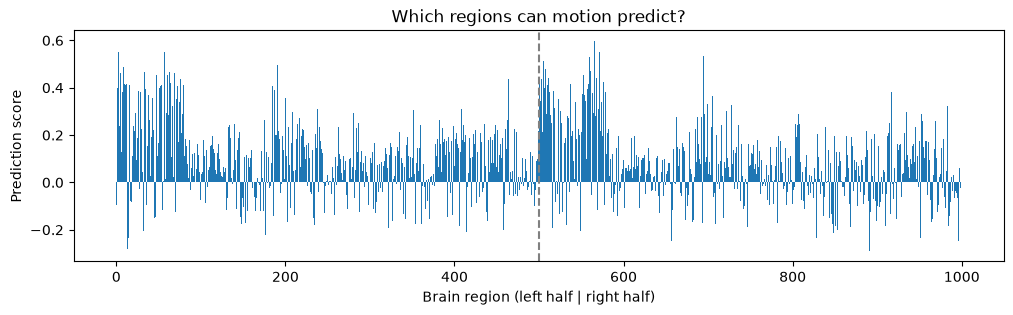

Best regions: [566 572  57   3 695 560 507 505   8 694]


In [5]:
from sklearn.linear_model import Ridge

lag = 3
X = motion[:-lag].reshape(-1, 1)
Y = brain[lag:]

split = int(len(X) * 0.7)
model = Ridge(alpha=1.0).fit(X[:split], Y[:split])
pred = model.predict(X[split:])

scores = np.array([np.corrcoef(pred[:, r], Y[split:, r])[0, 1] for r in range(1000)])

plt.figure(figsize=(12, 3))
plt.bar(range(1000), scores, width=1)
plt.axvline(500, color='gray', linestyle='--')
plt.xlabel('Brain region (left half | right half)')
plt.ylabel('Prediction score')
plt.title('Which regions can motion predict?')
plt.show()

print('Best regions:', np.argsort(scores)[-10:][::-1])